The three ODE solvers which will be used are Runge-Kutta 45 (RK45) which is a standard explicit solver, Radau, which is an implicit Runge-Kutta solver, and LSODA, which is an adaptive solver which in addition to having adaptive timesteps also switches between the non-stiff Adams method and the stiff BDF method depending on how fast the stiffness it detects.

Solver time:  0.002911499992478639 s
Number of time steps taken:  19
Accuracy: Idk
nfev/timesteps:  7.052631578947368


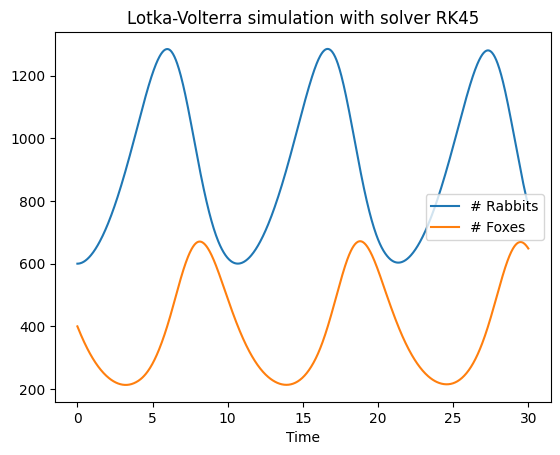

Solver time:  0.015313400013837963 s
Number of time steps taken:  38
Accuracy: Idk
nfev/timesteps:  9.552631578947368


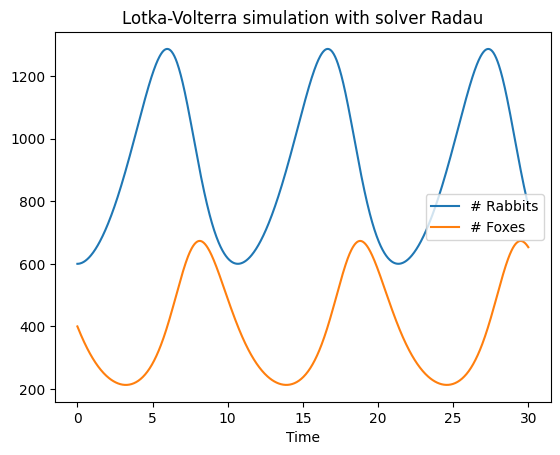

Solver time:  0.002884600020479411 s

Number of time steps taken:  61
Accuracy: Idk
nfev/timesteps:  2.2131147540983607


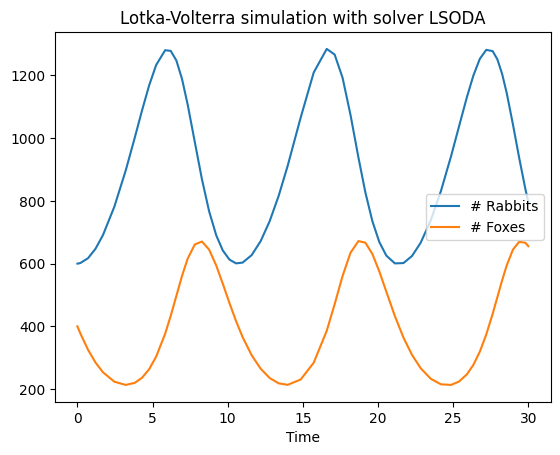

Solver  Runtime [s]  Steps  Error  nfev/step
  RK45     0.002911     19      0   7.052632
 Radau     0.015313     38      0   9.552632
 LSODA     0.002885     61      0   2.213115


In [ ]:
import time

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp 

runtimes = []
nsteps = []
errors = []
nfevOverSteps = []


# Lotka-Volterra
def lotka_volterra(t,y,a,b,c,d):
    R,F = y

    dRdt = a*R-b*F*R
    dFdt = c*R*F-d*F

    return [dRdt, dFdt]

a = 0.4
b = 0.001
c = 0.001
d = 0.9

# Initial conditions
y0 = [600, 400]

# Time interval
t = [0, 30]

# RK45
t_eval = np.linspace(t[0],t[1],1000)
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t,
    y0=y0,
    method='RK45',
    args=(a,b,c,d),
    #t_eval=t_eval,
    dense_output=True
)
tEnd = time.perf_counter()

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

t_plot = np.linspace(t[0], t[1], 1000)
y_plot = sol.sol(t_plot)
plt.figure()
plt.title('Lotka-Volterra simulation with solver RK45')
plt.plot(t_plot, y_plot[0,:],label='# Rabbits')
plt.plot(t_plot, y_plot[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()


# Radau
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t,
    y0=y0,
    method='Radau',
    args=(a,b,c,d),
    #t_eval=t_eval,
    dense_output=True
)
tEnd = time.perf_counter()

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))


t_plot = np.linspace(t[0],t[1],1000)
y_plot = sol.sol(t_plot)

plt.figure()
plt.title('Lotka-Volterra simulation with solver Radau')
plt.plot(t_plot, y_plot[0,:],label='# Rabbits')
plt.plot(t_plot, y_plot[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()


# LSODA
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t,
    y0=y0,
    method='LSODA',
    args=(a,b,c,d),
    #t_eval=t_eval,
    dense_output=True
)
tEnd = time.perf_counter()

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_LSODA, "s\n")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

t_plot = np.linspace(t[0],t[1],1000)
y_plot = sol.sol(t_plot)

plt.figure()
plt.title('Lotka-Volterra simulation with solver LSODA')
plt.plot(sol.t, sol.y[0,:],label='# Rabbits')
plt.plot(sol.t, sol.y[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()

# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

RK45 and LSODA seem to be similar in speed for and # of function evaluations per step. Radau slower and makes more calculations per step.

Solver time:  0.03137590002734214 s
Number of time steps taken:  265
Accuracy: Idk
nfev/timesteps:  6.59622641509434


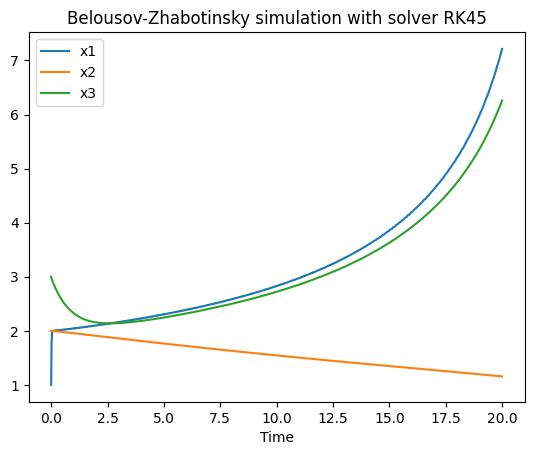

Solver time:  0.011865200009196997 s
Number of time steps taken:  19
Accuracy: Idk
nfev/timesteps:  9.263157894736842


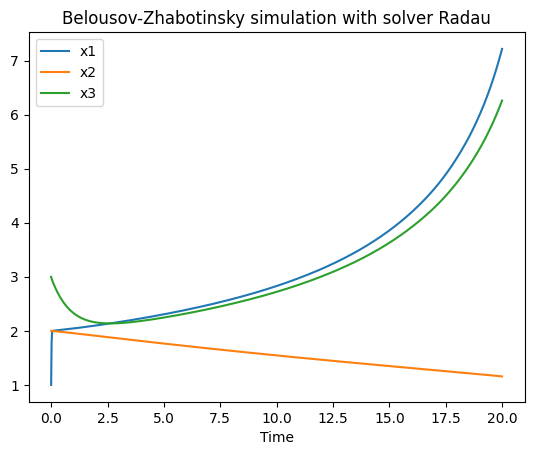

Solver time:  0.002155299996957183 s
Number of time steps taken:  58
Accuracy: Idk
nfev/timesteps:  2.3793103448275863


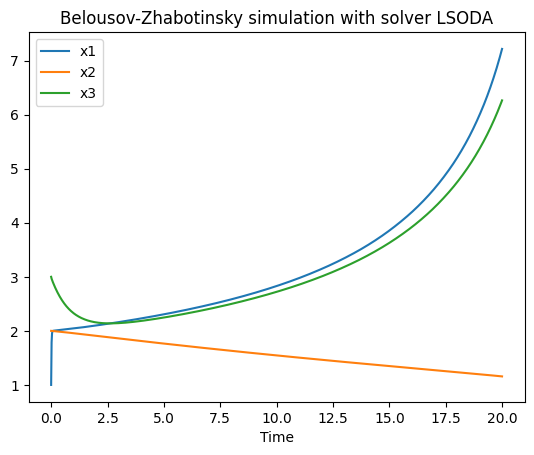

Solver  Runtime [s]  Steps  Error  nfev/step
  RK45     0.031376    265      0   6.596226
 Radau     0.011865     19      0   9.263158
 LSODA     0.002155     58      0   2.379310


In [32]:
def Belousov_Zhabotinsky(t, y, alpha, beta, gamma):
    x1,x2,x3 = y

    dx1dt = alpha*(x2+x1*(1-beta*x1-x2))
    dx2dt = 1/alpha*(x3-(1+x1)*x2)
    dx3dt = gamma*(x1-x3)

    return [dx1dt, dx2dt, dx3dt]

# Time interval
t = [0, 20]

# Initial conditions
y0 = [1, 2, 3]

# Constants
alpha = 77.27
beta = 8.375*10**(-6)
gamma = 1.161

t_eval = np.linspace(t[0], t[1], 1000)

# RK45

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t,
    y0 = y0,
    #t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="RK45",
    dense_output=True
)
tEnd = time.perf_counter()

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

t_plot = np.linspace(t[0], t[1], 1000)
y_plot = sol.sol(t_plot)

plt.figure()
plt.title('Belousov-Zhabotinsky simulation with solver RK45')
plt.plot(t_plot, y_plot[0,:],label='x1')
plt.plot(t_plot, y_plot[1,:],label='x2')
plt.plot(t_plot, y_plot[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()


# Radau

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t,
    y0 = y0,
    #t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="Radau",
    dense_output=True
)
tEnd = time.perf_counter()

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

t_plot = np.linspace(t[0], t[1], 1000)
y_plot = sol.sol(t_plot)

plt.figure()
plt.title('Belousov-Zhabotinsky simulation with solver Radau')
plt.plot(t_plot, y_plot[0,:],label='x1')
plt.plot(t_plot, y_plot[1,:],label='x2')
plt.plot(t_plot, y_plot[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()


# LSODA

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t,
    y0 = y0,
    #t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="LSODA",
    dense_output=True
)
tEnd = time.perf_counter()

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_LSODA, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

t_plot = np.linspace(t[0], t[1], 1000)
y_plot = sol.sol(t_plot)

plt.figure()
plt.title('Belousov-Zhabotinsky simulation with solver LSODA')
plt.plot(t_plot, y_plot[0,:],label='x1')
plt.plot(t_plot, y_plot[1,:],label='x2')
plt.plot(t_plot, y_plot[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()


# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Huge spike at ~25s. Correct or not?

Solver time:  0.03797770000528544 s
Number of time steps taken:  303
Accuracy: Idk
nfev/timesteps:  8.085808580858085


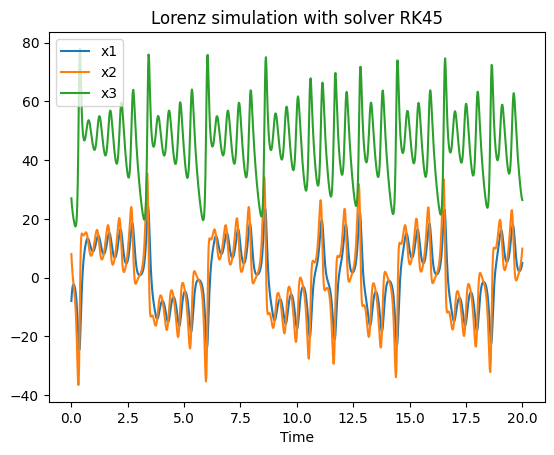

Solver time:  0.21551079995697364 s
Number of time steps taken:  578
Accuracy: Idk
nfev/timesteps:  8.849480968858131


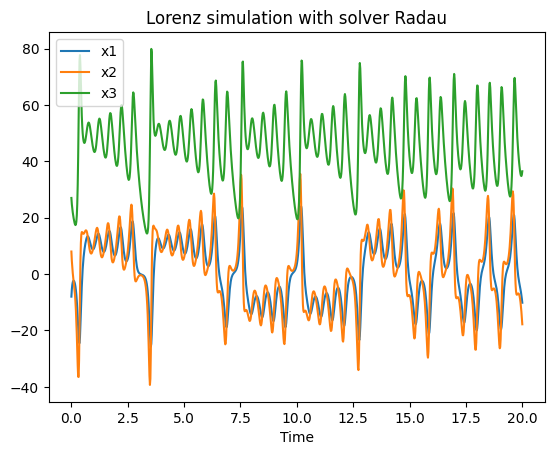

Solver time:  0.042874200036749244 s
Number of time steps taken:  1458
Accuracy: Idk
nfev/timesteps:  2.0651577503429355


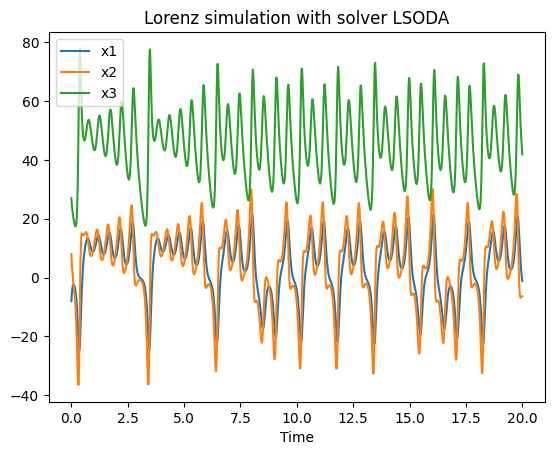

Solver  Runtime [s]  Steps  Error  nfev/step
  RK45     0.037978    303      0   8.085809
 Radau     0.215511    578      0   8.849481
 LSODA     0.042874   1458      0   2.065158


In [37]:
# Lorenz Chaos

def lorenz(t,y,sigma,rho,beta):
    [x1, x2, x3] = y

    dx1dt = sigma*(x2-x1)
    dx2dt = x1*(rho-x3)-x2
    dx3dt = x1*x2-beta*x3

    return [dx1dt, dx2dt, dx3dt]

# Constants
beta = 8/3
rho = 50
sigma = 10

# Initial conditions
x0 = [-8, 8, 27]

# Time interval
t = [0,20]

# RK45

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t,
    y0 = x0,
    args = (sigma, rho, beta),
    method = "RK45",
    dense_output=True
)
tEnd = time.perf_counter()

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

t_plot = np.linspace(t[0], t[1], 1000)
y_plot = sol.sol(t_plot)

plt.figure()
plt.title('Lorenz simulation with solver RK45')
plt.plot(t_plot, y_plot[0,:],label='x1')
plt.plot(t_plot, y_plot[1,:],label='x2')
plt.plot(t_plot, y_plot[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()


# Radau

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t,
    y0 = x0,
    args = (sigma, rho, beta),
    method = "Radau",
    dense_output=True
)
tEnd = time.perf_counter()

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

t_plot = np.linspace(t[0], t[1], 1000)
y_plot = sol.sol(t_plot)

plt.figure()
plt.title('Lorenz simulation with solver Radau')
plt.plot(t_plot, y_plot[0,:],label='x1')
plt.plot(t_plot, y_plot[1,:],label='x2')
plt.plot(t_plot, y_plot[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()

# LSODA

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t,
    y0 = x0,
    args = (sigma, rho, beta),
    method = "LSODA",
    dense_output=True
)
tEnd = time.perf_counter()

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_LSODA, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

t_plot = np.linspace(t[0], t[1], 1000)
y_plot = sol.sol(t_plot)

plt.figure()
plt.title('Lorenz simulation with solver LSODA')
plt.plot(t_plot, y_plot[0,:],label='x1')
plt.plot(t_plot, y_plot[1,:],label='x2')
plt.plot(t_plot, y_plot[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()

# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))